In [ ]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, mean_absolute_error


In [ ]:
df= pd.read_csv('hour.csv')
df.head()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [30]:
print(df.columns)
df.info()

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int

In [ ]:
df.isna().sum().sum()


np.int64(0)

In [ ]:
cols= ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday','workingday']

for col in cols:
    print(f"Values for {col}:\n")
    print(df[col].unique(),'\n')


Values for season:

[1 2 3 4] 

Values for yr:

[0 1] 

Values for mnth:

[ 1  2  3  4  5  6  7  8  9 10 11 12] 

Values for hr:

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23] 

Values for holiday:

[0 1] 

Values for weekday:

[6 0 1 2 3 4 5] 

Values for workingday:

[0 1] 



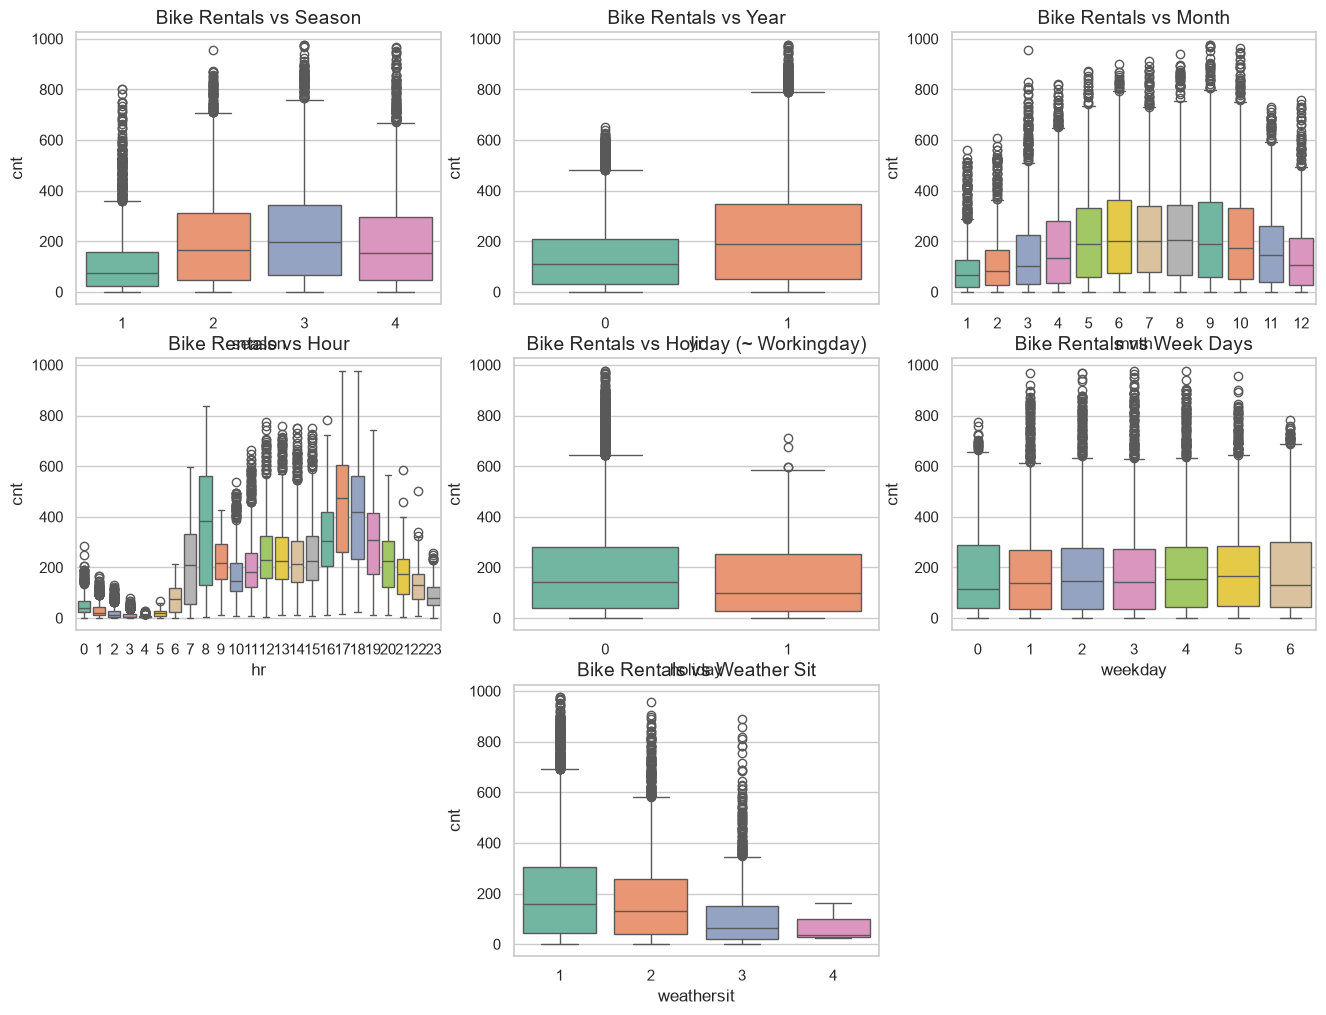

In [ ]:
sns.set_theme(style='whitegrid')
fig, axes= plt.subplots(3, 3, figsize=(16, 12))

sns.boxplot(x='season', y='cnt', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Bike Rentals vs Season', fontsize=14)

sns.boxplot(x='yr', y='cnt', data=df, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Bike Rentals vs Year', fontsize=14)

sns.boxplot(x='mnth', y='cnt', data=df, ax=axes[0, 2], palette='Set2')
axes[0, 2].set_title('Bike Rentals vs Month', fontsize=14)

sns.boxplot(x='hr', y='cnt', data=df, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Bike Rentals vs Hour', fontsize=14)

sns.boxplot(x='holiday', y='cnt', data=df, ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Bike Rentals vs Holiday (~ Workingday)', fontsize=14)

sns.boxplot(x='weekday', y='cnt', data=df, ax=axes[1, 2], palette='Set2')
axes[1, 2].set_title('Bike Rentals vs Week Days', fontsize=14)

fig.delaxes(axes[2, 0])

sns.boxplot(x='weathersit', y='cnt', data=df, ax=axes[2, 1], palette='Set2')
axes[2, 1].set_title('Bike Rentals vs Weather Sit', fontsize=14)

fig.delaxes(axes[2, 2])


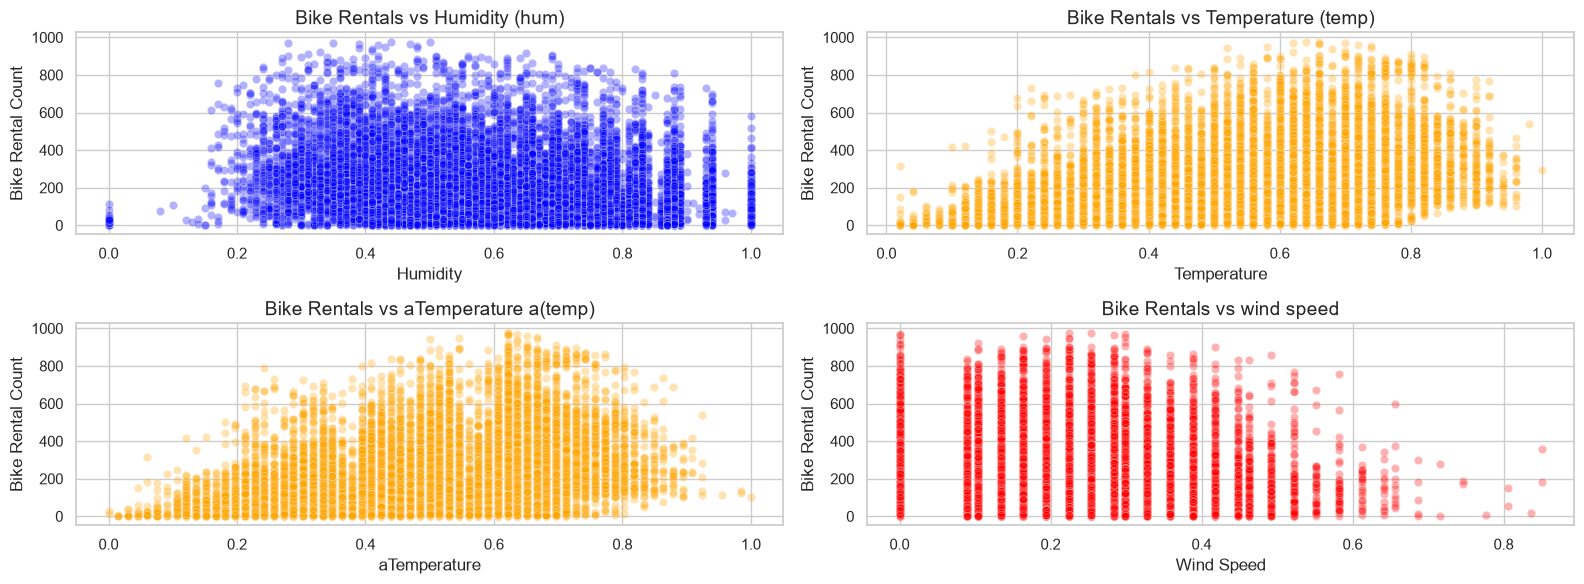

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(16, 6))


sns.scatterplot(
    x='hum', y='cnt', data=df, alpha=0.3, color='blue', ax=axes[0, 0]
)
axes[0, 0].set_title('Bike Rentals vs Humidity (hum)', fontsize=14)
axes[0, 0].set_xlabel('Humidity')
axes[0, 0].set_ylabel('Bike Rental Count')


sns.scatterplot(
    x='temp', y='cnt', data=df, alpha=0.3, color='orange', ax=axes[0, 1]
)
axes[0, 1].set_title('Bike Rentals vs Temperature (temp)', fontsize=14)
axes[0, 1].set_xlabel('Temperature')
axes[0, 1].set_ylabel('Bike Rental Count')

sns.scatterplot(
    x='atemp', y='cnt', data=df, alpha=0.3, color='orange', ax=axes[1, 0]
)
axes[1, 0].set_title('Bike Rentals vs aTemperature a(temp)', fontsize=14)
axes[1, 0].set_xlabel('aTemperature')
axes[1, 0].set_ylabel('Bike Rental Count')

sns.scatterplot(
    x='windspeed', y='cnt', data=df, alpha=0.3, color='red', ax=axes[1, 1]
)
axes[1, 1].set_title('Bike Rentals vs wind speed', fontsize=14)
axes[1, 1].set_xlabel('Wind Speed')
axes[1, 1].set_ylabel('Bike Rental Count')

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Bike Rentals')

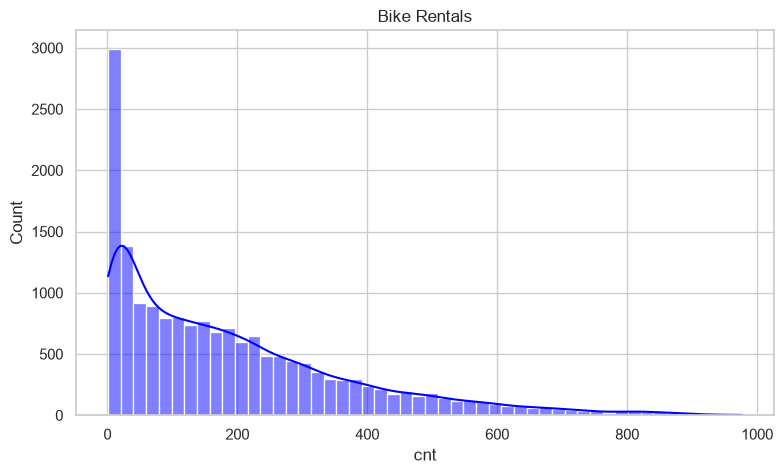

In [ ]:
plt.figure(figsize=(9, 5))
plt.subplot(1, 1, 1)
sns.histplot(df['cnt'], kde=True, bins= 50, color='blue')
plt.title('Bike Rentals')


In [ ]:
df['dteday'] = pd.to_datetime(df['dteday'])
df['day_of_week'] = (
    df['dteday'].dt.dayofweek
)
df['is_weekend']= df['weekday'].isin([5, 6]).astype(int)

df[['dteday', 'hr', 'weekday','day_of_week','is_weekend', 'workingday']].head(10)


,dteday,hr,weekday,day_of_week,is_weekend,workingday
0,2011-01-01,0,6,5,1,0
1,2011-01-01,1,6,5,1,0
2,2011-01-01,2,6,5,1,0
3,2011-01-01,3,6,5,1,0
4,2011-01-01,4,6,5,1,0
5,2011-01-01,5,6,5,1,0
6,2011-01-01,6,6,5,1,0
7,2011-01-01,7,6,5,1,0
8,2011-01-01,8,6,5,1,0
9,2011-01-01,9,6,5,1,0


In [ ]:
df= df.sort_values(by=['dteday','hr']).reset_index(drop=True)

#Lag Features
df['cnt_lag_1']=df['cnt'].shift(1)
df['cnt_lag_24']= df['cnt'].shift(24)

#Rolling Statistics
df['cnt_rolling_mean_3h']= df['cnt'].shift(1).rolling(window=3).mean()
df['cnt_rolling_mean_24h']= df['cnt'].shift(24).rolling(window=24).mean()

df= df.dropna().reset_index(drop=True)
print(df[['dteday', 'hr', 'cnt', 'cnt_lag_1', 'cnt_lag_24', 'cnt_rolling_mean_3h']].head(10))


      dteday  hr  cnt  cnt_lag_1  cnt_lag_24  cnt_rolling_mean_3h
0 2011-01-03   0    5        8.0        39.0            16.000000
1 2011-01-03   1    2        5.0        17.0             7.333333
2 2011-01-03   4    1        2.0        17.0             5.000000
3 2011-01-03   5    3        1.0         9.0             2.666667
4 2011-01-03   6   30        3.0         6.0             2.000000
5 2011-01-03   7   64       30.0         3.0            11.333333
6 2011-01-03   8  154       64.0         2.0            32.333333
7 2011-01-03   9   88      154.0         1.0            82.666667
8 2011-01-03  10   44       88.0         8.0           102.000000
9 2011-01-03  11   51       44.0        20.0            95.333333


In [38]:
df['cnt_log']= np.log1p(df['cnt'])

df.head()


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,casual,registered,cnt,day_of_week,is_weekend,cnt_lag_1,cnt_lag_24,cnt_rolling_mean_3h,cnt_rolling_mean_24h,cnt_log
0,48,2011-01-03,1,0,1,0,0,1,1,1,...,0,5,5,0,0,8.0,39.0,16.000000,41.041667,1.791759
1,49,2011-01-03,1,0,1,1,0,1,1,1,...,0,2,2,0,0,5.0,17.0,7.333333,41.083333,1.098612
2,50,2011-01-03,1,0,1,4,0,1,1,1,...,0,1,1,0,0,2.0,17.0,5.000000,40.125000,0.693147
3,51,2011-01-03,1,0,1,5,0,1,1,1,...,0,3,3,0,0,1.0,9.0,2.666667,39.166667,1.386294
4,52,2011-01-03,1,0,1,6,0,1,1,1,...,0,30,30,0,0,3.0,6.0,2.000000,38.875000,3.433987


In [ ]:
df = df.drop(columns=['instant','dteday','casual', 'registered', 'cnt'])
df.head()


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,day_of_week,is_weekend,cnt_lag_1,cnt_lag_24,cnt_rolling_mean_3h,cnt_rolling_mean_24h,cnt_log
0,1,0,1,0,0,1,1,1,0.22,0.1970,0.44,0.3582,0,0,8.0,39.0,16.000000,41.041667,1.791759
1,1,0,1,1,0,1,1,1,0.20,0.1667,0.44,0.4179,0,0,5.0,17.0,7.333333,41.083333,1.098612
2,1,0,1,4,0,1,1,1,0.16,0.1364,0.47,0.3881,0,0,2.0,17.0,5.000000,40.125000,0.693147
3,1,0,1,5,0,1,1,1,0.16,0.1364,0.47,0.2836,0,0,1.0,9.0,2.666667,39.166667,1.386294
4,1,0,1,6,0,1,1,1,0.14,0.1061,0.50,0.3881,0,0,3.0,6.0,2.000000,38.875000,3.433987


In [ ]:
X= df.drop(columns=['cnt_log'])
y= df['cnt_log']

X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42)


In [ ]:
xgb_model= xgb.XGBRegressor(
    n_estimators= 200, learning_rate= 0.1, max_depth=6, random_state=42
)
xgb_model.fit(X_train, y_train)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
lgb_model = lgb.LGBMRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42
)
lgb_model.fit(X_train, y_train)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000765 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1312
[LightGBM] [Info] Number of data points in the train set: 13865, number of used features: 18
[LightGBM] [Info] Start training from score 4.577675
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

,max_depth,6
,learning_rate,0.05
,n_estimators,200
,random_state,42
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [ ]:
y_pred_xgb_log = xgb_model.predict(X_test)
y_pred_lgb_log = lgb_model.predict(X_test)

y_test_orig = np.expm1(y_test)
y_pred_xgb = np.expm1(y_pred_xgb_log)
y_pred_lgb = np.expm1(y_pred_lgb_log)

xgb_rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_xgb))
xgb_mae = mean_absolute_error(y_test_orig, y_pred_xgb)

lgb_rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_lgb))
lgb_mae = mean_absolute_error(y_test_orig, y_pred_lgb)

print(f'XGBoost  -> RMSE: {xgb_rmse:.2f} | MAE: {xgb_mae:.2f}')
print(f'LightGBM -> RMSE: {lgb_rmse:.2f} | MAE: {lgb_mae:.2f}')


XGBoost  -> RMSE: 33.47 | MAE: 20.87
LightGBM -> RMSE: 35.70 | MAE: 22.05


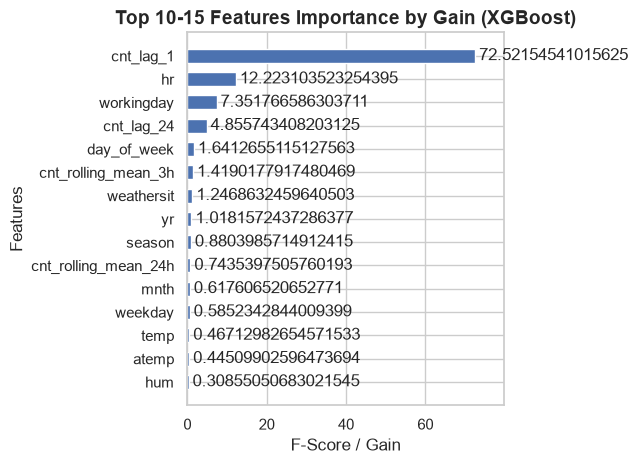

In [44]:
xgb.plot_importance(
    xgb_model, importance_type='gain', max_num_features=15, height=0.6
)
plt.title(
    'Top 10-15 Features Importance by Gain (XGBoost)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('F-Score / Gain', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()